# Which grid types are there?

The classification clusters the grids of the sample on a few key figures (chosen in
[01_sample_and_key_figures](01_sample_and_key_figures.ipynb)) and names the real grid closest to the centre of each
cluster as its representative. This notebook shows how many clusters the data support, whether k-means and a Gaussian
mixture model agree, how the clusters differ and what their representative grids look like.

**Needs:** a classification run (`pylovo-classify`, see [Classifying grids](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html)), the `notebooks` extra and a
`.env` that points to the database (see `notebook_tutorials/README.md`). The notebook only reads. The stored outputs
show a classification of 501 Bavarian PLZ, drawn from LV version 1 of the pylovo results database.

In [1]:
# Parameters
classification_id = None  # None: CLASSIFICATION_VERSION of config_classification.yaml
version_id = None  # None: VERSION_ID of config_generation_lv.yaml
algorithm = "kmeans"  # clustering shown after the comparison: "kmeans" or "gmm" (tied covariance)
n_clusters = None  # None: the numbers of clusters stored with the classification

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from pylovo.classification.clustering.clustering_algorithms import gmm_tied_clustering, kmeans_clustering
from pylovo.classification.database_communication.database_communication import DatabaseCommunication
from pylovo.config_loader import NO_OF_CLUSTERS_ALLOWED
from pylovo.database.database_client import DatabaseClient
from pylovo.plotting.classification import (
    plot_ch_index_for_clustering_algos,
    plot_clusters_in_parameter_space,
    plot_clusters_per_regiostar_class,
    plot_db_index_for_clustering_algos,
    plot_percentage_of_clusters,
    plot_radar_graph,
    plot_representative_grids,
)

plt.rcParams["figure.dpi"] = 80  # moderate resolution of the stored figures
dc = DatabaseCommunication(classification_id, version_id)
choices = dc.get_classification_choices()
parameters = choices["list_of_clustering_parameters"]
grids = dc.municipal_register_with_clustering_parameters_for_classification_version()
print(f"Classification {dc.classification_id}, version {dc.version_id}: {len(grids)} grids in {grids['plz'].nunique()} PLZ")
choices

Database connection is constructed. 


Classification 2, version 1: 26049 grids in 501 PLZ


{'list_of_clustering_parameters': ['no_house_connections',
  'no_household_equ_per_branch',
  'max_trafo_dis'],
 'n_clusters_kmeans': 4,
 'n_clusters_gmm': 6,
 'additional_filtering': False,
 'transform': 'yeo-johnson',
 'exclude_infeasible': True}

## How many clusters do the data support?

`pylovo-classify` compares the numbers of `NO_OF_CLUSTERS_ALLOWED` with the Calinski-Harabasz index and takes the best
one of k-means and of the GMM with tied covariance ([Step 6b](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-6b-number-of-clusters)). The Davies-Bouldin
index is a second opinion.

,algorithm,no_clusters_ch,ch_index,no_clusters_db,db_index
0,kmeans,4,18341.293674,7,0.899299
1,gmm_full,6,15263.967313,5,0.979508
2,gmm_diag,4,17090.962025,4,0.927172
3,gmm_tied,6,16598.152264,7,0.900226
4,gmm_sph,4,17561.724268,5,0.793525


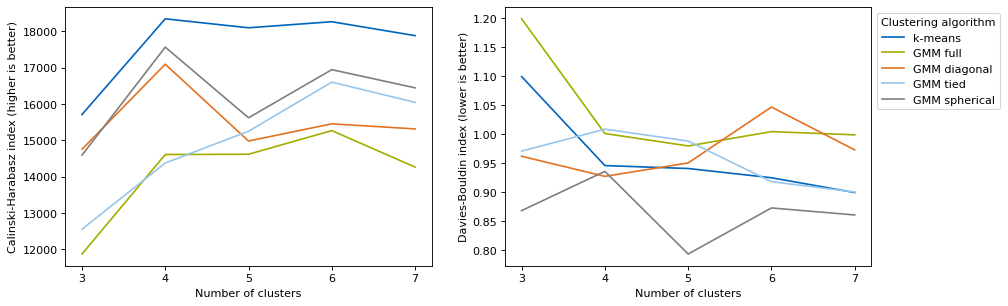

In [3]:
fig, (ch_ax, db_ax) = plt.subplots(1, 2, figsize=(13, 4.2))
transform = choices["transform"]  # the key figures are transformed as in the run, then standardised
ch = plot_ch_index_for_clustering_algos(grids, NO_OF_CLUSTERS_ALLOWED, parameters, ax=ch_ax, legend=False,
                                        transform=transform)
db = plot_db_index_for_clustering_algos(grids, NO_OF_CLUSTERS_ALLOWED, parameters, ax=db_ax, transform=transform)
ch.merge(db, on="algorithm", suffixes=("_ch", "_db"))

The Calinski-Harabasz index rewards compact clusters that lie far apart (higher is better), the Davies-Bouldin
index penalises clusters that overlap (lower is better). Here the Calinski-Harabasz index gives k-means 4 clusters,
with 5 and 6 less than 2 % lower, and the tied GMM 6. The Davies-Bouldin index prefers 7 for both. k-means has the
highest Calinski-Harabasz index of all algorithms. The run stored 4 and 6 (printed above).

## Do k-means and the GMM find the same clusters?

Both algorithms cluster the transformed and standardised key figures; the GMM with tied covariance allows elongated clusters, all
of the same shape.

In [4]:
n_kmeans, n_gmm = (n_clusters, n_clusters) if n_clusters else (choices["n_clusters_kmeans"], choices["n_clusters_gmm"])
kmeans_grids, kmeans_representatives = kmeans_clustering(grids.copy(), parameters, n_kmeans, transform=transform)
gmm_grids, gmm_representatives = gmm_tied_clustering(grids.copy(), parameters, n_gmm, transform=transform)
print(f"Adjusted Rand index: {adjusted_rand_score(kmeans_grids['clusters'], gmm_grids['clusters']):.2f}")
pd.crosstab(kmeans_grids["clusters"], gmm_grids["clusters"], rownames=["k-means"], colnames=["GMM"])

converged: True
no of iterations 7
Adjusted Rand index: 0.40


GMM,0,1,2,3,4,5
k-means,,,,,,
0,1567,3102,112,23,0,11
1,0,397,3551,823,0,7
2,0,1940,0,2508,39,3855
3,0,0,95,2731,4876,412


The adjusted Rand index is 1 for identical clusterings and about 0 for random ones, here 0.40. The table counts the
grids per pair of clusters. k-means cluster 0 (the small grids) splits into GMM cluster 0 (mostly grids without a
feeder) and 1, k-means cluster 1 (the long grids) lies mostly in GMM cluster 2, and the GMM divides the two large
k-means clusters more finely: cluster 2 into 5, 3 and 1, cluster 3 into 4 and 3. Both algorithms number their
clusters by the households of the representative grid, so the same number need not be the same cluster.

## Where do the clusters lie?

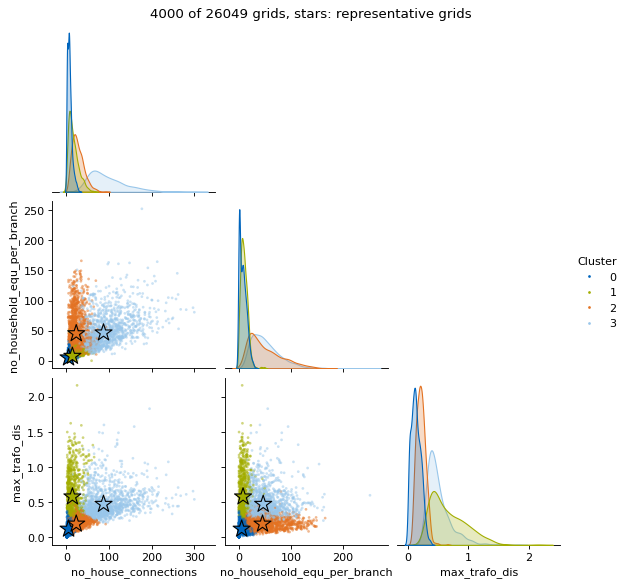

In [5]:
clustered, representatives = {"kmeans": (kmeans_grids, kmeans_representatives),
                              "gmm": (gmm_grids, gmm_representatives)}[algorithm]
fig = plot_clusters_in_parameter_space(clustered, parameters, representatives)

Every point is a grid in the colour of its cluster, the stars are the representative grids. In the stored output
(k-means) the clusters separate along the three key figures: cluster 1 (green) by the long paths from the station,
cluster 2 (orange) by many household equivalents per feeder with few buildings (apartment buildings), cluster 3
(light blue) by many buildings. Cluster 0 (blue) holds the small grids close to the origin.

## How common is each cluster, and where?

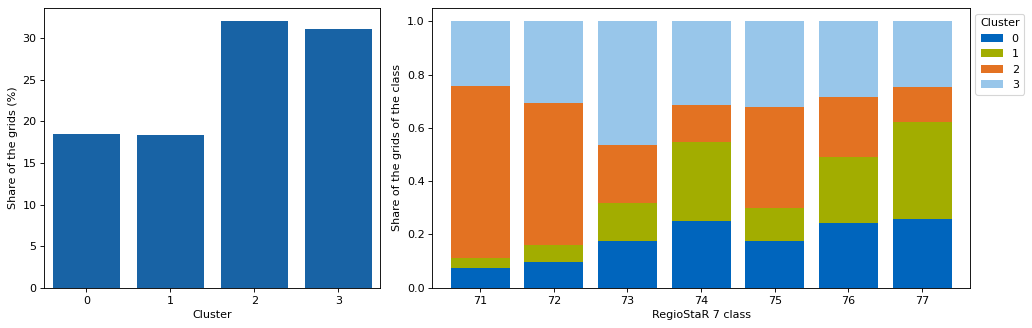

In [6]:
fig, (share_ax, class_ax) = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=[1, 1.6])
plot_percentage_of_clusters(clustered, ax=share_ax)
plot_clusters_per_regiostar_class(clustered, ax=class_ax)
fig.tight_layout()

Left: the dense grids of cluster 2 and the large grids of cluster 3 make up about a third of all grids each, the
small grids of cluster 0 and the long grids of cluster 1 18 % each. Right: the mix in each RegioStaR 7 class. In the
metropolis (71) two thirds of the grids belong to cluster 2, the dense grids of apartment buildings. Towards the rural
classes the small grids (0) and the long grids (1) take over, the long grids up to 37 % in class 77.

## What distinguishes the clusters?

The median of every cluster describes its typical grid; the representative is the real grid closest to the cluster
centre in the standardised clustering parameters.

In [7]:
columns = list(dict.fromkeys(parameters + ["no_house_connections", "no_households", "no_branches", "transformer_mva",
                                           "cable_length_km", "max_trafo_dis"]))
clustered.groupby("clusters")[columns].median().round(3)

,no_house_connections,no_household_equ_per_branch,max_trafo_dis,no_households,no_branches,transformer_mva,cable_length_km
clusters,,,,,,,
0,6.0,6.000,0.118,6.0,1.0,0.40,0.273
1,13.0,9.000,0.590,17.0,2.0,0.25,1.457
2,24.0,39.985,0.206,110.0,3.0,0.40,0.858
3,84.0,44.461,0.453,152.0,3.0,0.40,3.012


In [8]:
representatives.set_index("clusters")[["plz", "kcid", "bcid"] + columns]

,plz,kcid,bcid,no_house_connections,no_household_equ_per_branch,max_trafo_dis,no_households,no_branches,transformer_mva,cable_length_km
clusters,,,,,,,,,,
0,91355,1,5,5,5.000000,0.121290,8,1,0.25,0.227021
1,83486,1,33,14,7.666667,0.579998,24,3,0.25,1.591725
2,97688,2,50,23,45.182464,0.193213,92,2,0.40,0.935537
3,91166,1,16,87,46.500000,0.474511,98,2,0.40,3.083876


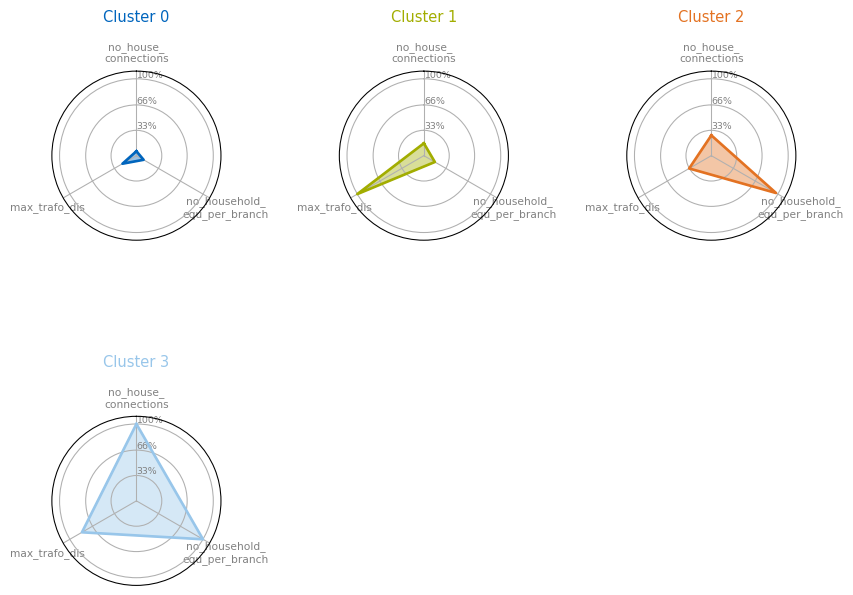

In [9]:
fig = plot_radar_graph(representatives, parameters, figsize=(10, 7.5))

The clusters differ in size, density and length. Here the median grid of cluster 0 has 6 buildings on 0.27 km of
cable, cluster 1 is a long rural grid (longest path 0.59 km, 250 kVA), cluster 2 a short, dense grid of 24 buildings
with 110 households, cluster 3 a large grid of 84 buildings and 152 households on 3 km of cable. The radar shows
every clustering parameter of a representative relative to the largest representative.

## What do the representative grids look like?

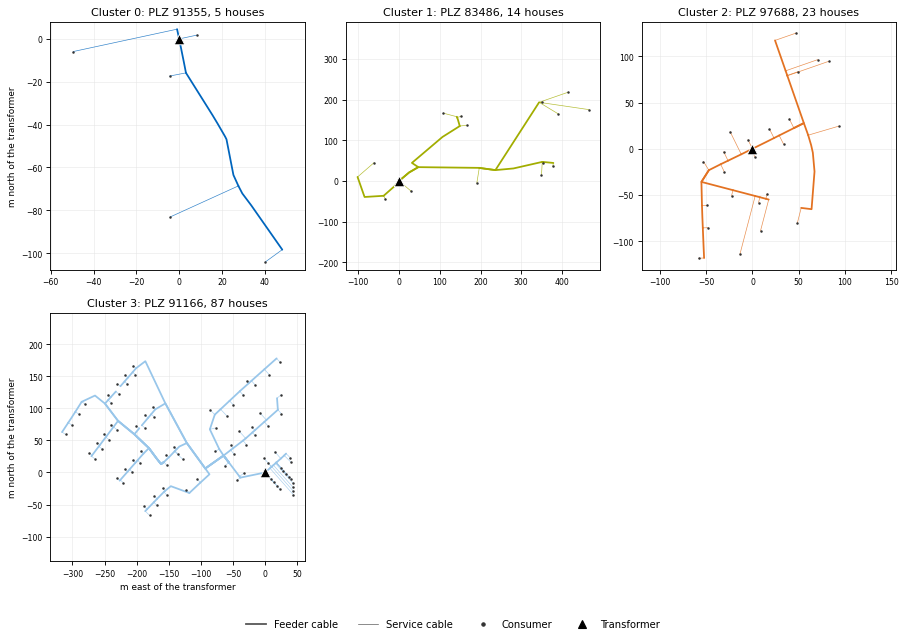

In [10]:
with DatabaseClient() as client:
    nets = [client.read_net_db(int(r.plz), int(r.kcid), int(r.bcid), version_id=dc.version_id)
            for r in representatives.itertuples()]
titles = [f"Cluster {r.clusters}: PLZ {r.plz}, {r.no_house_connections} houses" for r in representatives.itertuples()]
fig = plot_representative_grids(nets, titles)

Each panel is the representative grid of one cluster around its transformer (triangle): feeder cables thick,
service cables thin, consumers as dots. The axes are in metres, and every panel has its own scale: the farthest
building of the rural grid of cluster 1 is 580 m of cable from its station, that of the dense grid of cluster 2 190 m.
`plot_representative_grids(nets, titles, same_scale=True)` draws all panels at the extent of the largest grid.

## Next

The result of the run is stored per transformer in `pylovo.transformer_classified` and, with the grid data, in the view
`pylovo.transformer_classified_with_grid`: add it to QGIS and colour it by `kmeans_clusters` or `gmm_clusters`
([Step 7](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-7-clustering-and-result)). A pandapower net of any grid:
`DatabaseClient().read_net_db(plz, kcid, bcid)`.